In [9]:
import xgboost

print(xgboost.__version__)

1.7.6


In [10]:
# Train an XGBoost classifier with the breast cancer dataset.
import xgboost as xgb
from xgboost import plot_importance, XGBClassifier
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

dataset = load_breast_cancer()
X_features = dataset.data
y_label = dataset.target

In [11]:
df = pd.DataFrame(X_features, columns=dataset.feature_names)
df["target"] = y_label
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [12]:
print(dataset.target_names)
print(df["target"].value_counts())

['malignant' 'benign']
1    357
0    212
Name: target, dtype: int64


In [13]:
X_features = df.drop(columns="target")
y_label = df["target"]

# Split the data into training, validation, and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_label, test_size=0.2, random_state=156, stratify=y_label
)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=156, stratify=y_train
)

print("Training data:", X_train.shape, "Test data:", X_test.shape)
print("Fit data:", X_tr.shape, "Validation data:", X_val.shape)

Training data: (455, 30) Test data: (114, 30)
Fit data: (409, 30) Validation data: (46, 30)


In [14]:
# DMatrix is the data format used by the native XGBoost API.
dtr = xgb.DMatrix(data=X_tr, label=y_tr)
dval = xgb.DMatrix(data=X_val, label=y_val)
dtest = xgb.DMatrix(data=X_test, label=y_test)

In [15]:
params = {
    "max_depth": 3,
    "eta": 0.05,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
}
num_rounds = 400

In [16]:
# Stop training when validation performance no longer improves.
eval_list = [(dtr, "train"), (dval, "eval")]
xgb_model = xgb.train(
    params=params,
    dtrain=dtr,
    num_boost_round=num_rounds,
    evals=eval_list,
    early_stopping_rounds=50,
    verbose_eval=False,
)
print("Best iteration:", xgb_model.best_iteration)

Best iteration: 229


In [17]:
# Convert predicted probabilities to class labels at a 0.5 threshold.
pred_probs = xgb_model.predict(dtest)
preds = (pred_probs > 0.5).astype(int)
print("Predicted probabilities:", np.round(pred_probs[:10], 3))
print("Predicted labels:", preds[:10])

Predicted probabilities: [0.001 0.999 0.992 0.999 0.975 0.996 0.998 0.999 0.999 0.998]
Predicted labels: [0 1 1 1 1 1 1 1 1 1]


In [18]:
def get_clf_eval(y_true, pred, pred_proba):
    confusion = confusion_matrix(y_true, pred)
    accuracy = accuracy_score(y_true, pred)
    precision = precision_score(y_true, pred)
    recall = recall_score(y_true, pred)
    f1 = f1_score(y_true, pred)
    roc_auc = roc_auc_score(y_true, pred_proba)

    print("Confusion matrix:\n", confusion)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 score: {f1:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")

In [19]:
get_clf_eval(y_test, preds, pred_probs)

Confusion matrix:
 [[41  1]
 [ 0 72]]
Accuracy: 0.9912
Precision: 0.9863
Recall: 1.0000
F1 score: 0.9931
ROC AUC: 0.9937


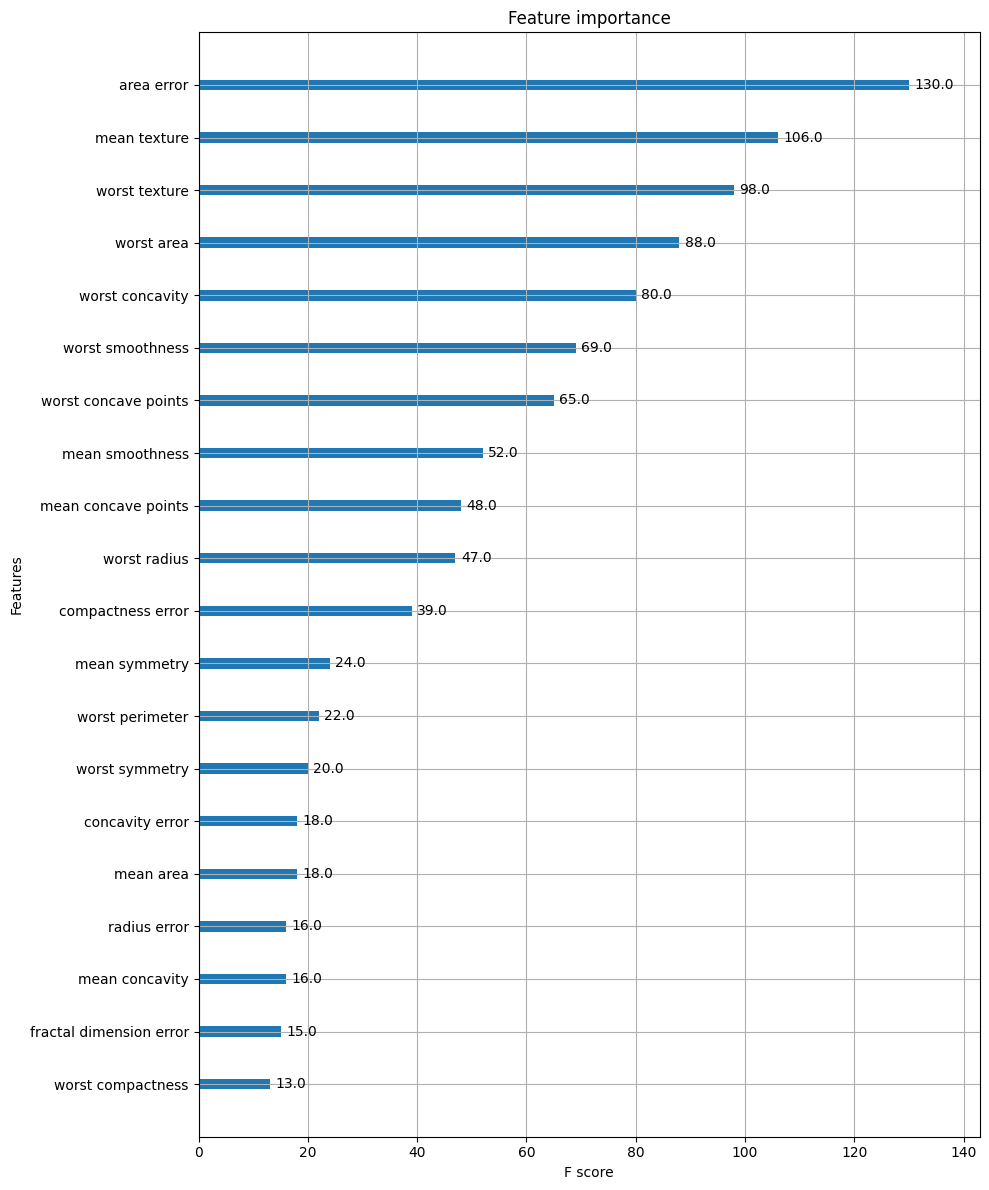

In [20]:
# Plot feature importance from the trained booster.
fig, ax = plt.subplots(figsize=(10, 12))
plot_importance(xgb_model, ax=ax, max_num_features=20)
fig.tight_layout()
plt.show()

In [21]:
# Train an XGBoost classifier using the scikit-learn API.
xgb_wrapper = XGBClassifier(
    n_estimators=400,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=156,
)
xgb_wrapper.fit(X_train, y_train)
w_preds = xgb_wrapper.predict(X_test)
w_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

In [22]:
get_clf_eval(y_test, w_preds, w_pred_proba)

Confusion matrix:
 [[41  1]
 [ 0 72]]
Accuracy: 0.9912
Precision: 0.9863
Recall: 1.0000
F1 score: 0.9931
ROC AUC: 0.9947


In [23]:
# Use the validation set to select the early stopping point.
xgb_wrapper = XGBClassifier(
    n_estimators=400,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    early_stopping_rounds=50,
    random_state=156,
)
xgb_wrapper.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)
print("Best iteration:", xgb_wrapper.best_iteration)

Best iteration: 398


In [24]:
# Evaluate the final model on the held-out test set.
ws100_pred = xgb_wrapper.predict(X_test)
ws100_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]
get_clf_eval(y_test, ws100_pred, ws100_pred_proba)

Confusion matrix:
 [[41  1]
 [ 0 72]]
Accuracy: 0.9912
Precision: 0.9863
Recall: 1.0000
F1 score: 0.9931
ROC AUC: 0.9947


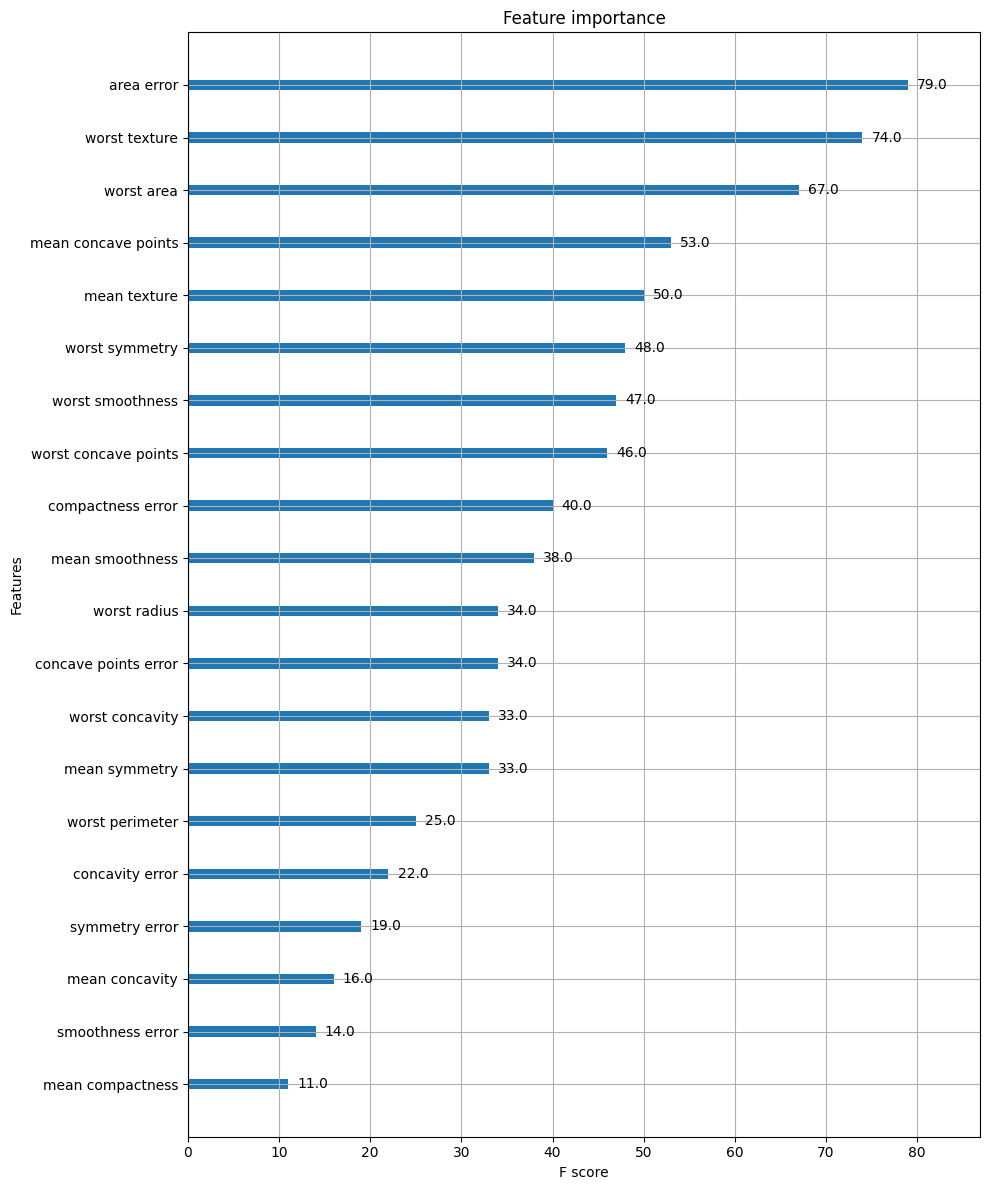

In [25]:
# Plot feature importance from the early-stopped classifier.
fig, ax = plt.subplots(figsize=(10, 12))
plot_importance(xgb_wrapper, ax=ax, max_num_features=20)
fig.tight_layout()
plt.show()